# BRD of Ames_Housing_Data

# Ames Housing Dataset Summary:

The dataset contains information about houses in Ames, Iowa, mainly related to their location, construction, quality, lot size, and selling price.

Total records: 2,930 houses
Total columns: 10


1.PID: Unique property ID for each house(Property Identity)
2.Neighborhood: Location of the house within Ames. There are 28 neighborhoods in the dataset.
3.Year Built: Year in which the house was originally constructed.
4.Overall Qual: Overall material and finish quality, rated from 1 (Very Poor) to 10 (Very Excellent).
5.Kitchen Qual: Kitchen quality, ranging from Poor to Excellent.
6.Exter Qual: Quality of the house's exterior material.
7.Lot Area: Size of the property lot in square feet.
8.SalePrice: Final selling price of the property in dollars.
9.Date Built: Indicates the day,month and  year in which the house was originally constructed

# Main Objective:

The main goal is to understand what makes a house expensive or less expensive(affordable) in Ames, Iowa.

So basically we will check different factors such as:

1.Property Quality:  Better-quality houses may have higher prices.
2.Neighborhood: Houses in some areas may be more expensive than others.
3.Year Built:Newer houses may have higher selling prices.
4.Kitchen Quality : Houses with better kitchens may sell for more.
5.Exterior Quality: Better-quality materials and finishing may increase the price.
6.Lot Area: A house with a larger land area may have a higher selling price.

# One-Line summary
We are analyzing the housing data to find out which features have the biggest impact on the selling price of a house.


# Section A — Setup, Loading & Inspection

A1.Import the four libraries and set the seaborn style to "whitegrid".

In [134]:
# Import the dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# set the seaborn style to "whitegrid"
sns.set_style("whitegrid")

A2.Load "Ames_Housing_Subset.csv" into a DataFrame called "df".
Display the shape of the DataFrame, the first 5 rows, and complete information about data

In [135]:
df=pd.read_csv(r"C:\Users\raval\Downloads\Ames_Housing_Subset.csv")
df.head()

,PID,Neighborhood,Year Built,Overall Qual,Kitchen Qual,Exter Qual,Lot Area,SalePrice,Date Built,Unnamed: 9
0,526301100,NAmes,1960,6,TA,TA,31770,215000,01-01-60,NaN
1,526350040,NAmes,1961,5,TA,TA,11622,105000,01-02-61,NaN
2,526351010,NAmes,1958,6,Gd,TA,14267,172000,01-03-58,NaN
3,526353030,NAmes,1968,7,Ex,Gd,11160,244000,01-04-68,NaN
4,527105010,Gilbert,1997,5,TA,TA,13830,189900,01-05-97,NaN


In [136]:
print("The number of rows and columns present in ames data:",df.shape)

The number of rows and columns present in ames data: (2930, 10)


In [137]:
print("The complete information about ames data is:")
print("---------------------------------------------")
df.info()

The complete information about ames data is:
---------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PID           2930 non-null   int64  
 1   Neighborhood  2930 non-null   object 
 2   Year Built    2930 non-null   int64  
 3   Overall Qual  2930 non-null   int64  
 4   Kitchen Qual  2930 non-null   object 
 5   Exter Qual    2930 non-null   object 
 6   Lot Area      2930 non-null   int64  
 7   SalePrice     2930 non-null   int64  
 8   Date Built    2930 non-null   object 
 9   Unnamed: 9    0 non-null      float64
dtypes: float64(1), int64(5), object(4)
memory usage: 229.0+ KB


A3.Check the DataFrame for missing values column by column & also check whether the "PID" column (a unique property ID) has any duplicate values.

In [138]:
print("The missing values in the ames data:")
df.isnull().sum()

The missing values in the ames data:


PID                0
Neighborhood       0
Year Built         0
Overall Qual       0
Kitchen Qual       0
Exter Qual         0
Lot Area           0
SalePrice          0
Date Built         0
Unnamed: 9      2930
dtype: int64

In [139]:
print("The duplicate values present in PID column is:",df.PID.duplicated().sum())

The duplicate values present in PID column is: 0


In [140]:
with open(r"C:\Users\raval\Downloads\Ames_Housing_Subset_Feature_Description.txt") as file:
    data=file.read()
print(data)


PID: Property ID of the house

Neighborhood: Physical locations within Ames city limits

       Blmngtn	Bloomington Heights
       Blueste	Bluestem
       BrDale	Briardale
       BrkSide	Brookside
       ClearCr	Clear Creek
       CollgCr	College Creek
       Crawfor	Crawford
       Edwards	Edwards
       Gilbert	Gilbert
       IDOTRR	Iowa DOT and Rail Road
       MeadowV	Meadow Village
       Mitchel	Mitchell
       Names	North Ames
       NoRidge	Northridge
       NPkVill	Northpark Villa
       NridgHt	Northridge Heights
       NWAmes	Northwest Ames
       OldTown	Old Town
       SWISU	South & West of Iowa State University
       Sawyer	Sawyer
       SawyerW	Sawyer West
       Somerst	Somerset
       StoneBr	Stone Brook
       Timber	Timberland
       Veenker	Veenker

Year Built: Original construction date

Overall Qual: Rates the overall material and finish of the house

       10	Very Excellent
       9	Excellent
       8	Very Good
       7	Good
       6	Above Average
       5	Aver

# Section B Numerical Analysis(Numpy-Numerical Python)

B1.Convert the "SalePrice" column to a NumPy array called "prices".
Using NumPy functions, compute and print its mean, median, standard deviation, minimum, maximum,
and the 25th and 75th percentiles.

In [141]:
df.columns

Index(['PID', 'Neighborhood', 'Year Built', 'Overall Qual', 'Kitchen Qual',
       'Exter Qual', 'Lot Area', 'SalePrice', 'Date Built', 'Unnamed: 9'],
      dtype='object')

In [142]:
print("Convert the SalePrice column to numpy array")
prices= df["SalePrice"].to_numpy()
prices

Convert the SalePrice column to numpy array


array([215000, 105000, 172000, ..., 132000, 170000, 188000], shape=(2930,))

In [143]:
prices=df["SalePrice"].values
prices

array([215000, 105000, 172000, ..., 132000, 170000, 188000], shape=(2930,))

In [144]:
# Statistical Analysis of prices array

print("Mean of prices array:",np.mean(prices))
print("Median of prices array:",np.median(prices))
print("Standard deviation of prices array:",np.std(prices))
print("Maximum value of prices array:",np.max(prices))
print("Minimum value of prices array:",np.min(prices))
print("25th percentile of prices array:",np.percentile(prices,25))
print("75th percentile of prices array:",np.percentile(prices,75))

Mean of prices array: 180796.0600682594
Median of prices array: 160000.0
Standard deviation of prices array: 79873.05865192253
Maximum value of prices array: 755000
Minimum value of prices array: 12789
25th percentile of prices array: 129500.0
75th percentile of prices array: 213500.0


B2. Convert Lot Area to a NumPy array lot_area. Using vectorized arithmetic
calculate price_per_sqft = prices / lot_area. Use np.argmax() and np.argmin() 
To find the PID of the houses with the highest and lowest price per square foot.

In [145]:
print("Convert the Lot Area column into numpy array")

lot_area= df["Lot Area"].to_numpy()
lot_area

Convert the Lot Area column into numpy array


array([31770, 11622, 14267, ..., 10441, 10010,  9627], shape=(2930,))

In [146]:
lot_area= df["Lot Area"].values
lot_area

array([31770, 11622, 14267, ..., 10441, 10010,  9627], shape=(2930,))

In [147]:
print("Create a new array names price_per_sqft")

price_per_sqft = prices/lot_area
price_per_sqft

Create a new array names price_per_sqft


array([ 6.76739062,  9.03458957, 12.05579309, ..., 12.6424672 ,
       16.98301698, 19.52840968], shape=(2930,))

In [148]:
max_1 = np.argmax(price_per_sqft)
print("Index position of the house with the highest price per square ft:",max_1)

Index position of the house with the highest price per square ft: 565


In [149]:
min_1 =np.argmin(price_per_sqft)
print("Index position of the house with the lowest price per square ft:",min_1)

Index position of the house with the lowest price per square ft: 1553


In [150]:
print("PID of the house with the highest price square per ft:",df.iloc[np.argmax(price_per_sqft)]["PID"])

PID of the house with the highest price square per ft: 533206020


In [151]:
print("PID of the house with lowest price square per ft:",df.iloc[np.argmin(price_per_sqft)]["PID"])

PID of the house with lowest price square per ft: 910251050


In [152]:
df["Price_Per_Sqft"]=price_per_sqft
df.head()

,PID,Neighborhood,Year Built,Overall Qual,Kitchen Qual,Exter Qual,Lot Area,SalePrice,Date Built,Unnamed: 9,Price_Per_Sqft
0,526301100,NAmes,1960,6,TA,TA,31770,215000,01-01-60,NaN,6.767391
1,526350040,NAmes,1961,5,TA,TA,11622,105000,01-02-61,NaN,9.034590
2,526351010,NAmes,1958,6,Gd,TA,14267,172000,01-03-58,NaN,12.055793
3,526353030,NAmes,1968,7,Ex,Gd,11160,244000,01-04-68,NaN,21.863799
4,527105010,Gilbert,1997,5,TA,TA,13830,189900,01-05-97,NaN,13.731020


B3. Using np.where, create price_flag labeling houses as "Expensive" 
if SalePrice is above the median, otherwise "Affordable".
Print the count of houses in each category using np.unique()

In [153]:
median_value = np.median(prices)
print("Median Sale Price of the houses:",median_value)

Median Sale Price of the houses: 160000.0


In [154]:
price_flag=np.where(prices>median_value,"Expensive","Affordable")
price_flag

array(['Expensive', 'Affordable', 'Expensive', ..., 'Affordable',
       'Expensive', 'Expensive'], shape=(2930,), dtype='<U10')

In [155]:
df["Price_flag"]=price_flag
df.head()

,PID,Neighborhood,Year Built,Overall Qual,Kitchen Qual,Exter Qual,Lot Area,SalePrice,Date Built,Unnamed: 9,Price_Per_Sqft,Price_flag
0,526301100,NAmes,1960,6,TA,TA,31770,215000,01-01-60,NaN,6.767391,Expensive
1,526350040,NAmes,1961,5,TA,TA,11622,105000,01-02-61,NaN,9.034590,Affordable
2,526351010,NAmes,1958,6,Gd,TA,14267,172000,01-03-58,NaN,12.055793,Expensive
3,526353030,NAmes,1968,7,Ex,Gd,11160,244000,01-04-68,NaN,21.863799,Expensive
4,527105010,Gilbert,1997,5,TA,TA,13830,189900,01-05-97,NaN,13.731020,Expensive


In [156]:
no_of_houses = np.unique(price_flag,return_counts=True)
print("House count by price category (Affordable vs Expensive) is:",no_of_houses)
print("The number of affordable houses is (1467),higher than the number of expensive houses(1463).")

House count by price category (Affordable vs Expensive) is: (array(['Affordable', 'Expensive'], dtype='<U10'), array([1467, 1463]))
The number of affordable houses is (1467),higher than the number of expensive houses(1463).


B4.Convert Year Built to a NumPy array and use boolean masking to count houses built after 2000.

In [157]:
# Convert the Year Built column into numpy array
year_built = df["Year Built"].to_numpy()
year_built

array([1960, 1961, 1958, ..., 1992, 1974, 1993], shape=(2930,))

In [158]:
year_built = df["Year Built"].to_numpy()
year_built

array([1960, 1961, 1958, ..., 1992, 1974, 1993], shape=(2930,))

In [159]:
houses_aftr_2000 =np.sum(year_built>2000)
print("The  total number of houses built after year 2000 is:",houses_aftr_2000)

The  total number of houses built after year 2000 is: 735


In [160]:
boolean_masking = year_built>2000
boolean_masking

array([False, False, False, ..., False, False, False], shape=(2930,))

B5. Calculate the z-scores of prices using NumPy, then use boolean indexing to count houses with |z| > 3, identifying sale-price outliers.

In [161]:
price_mean = np.mean(prices).round(2)
print("Mean value of prices array is:",price_mean)
price_std=np.std(prices).round(2)
print("Standard deviation of prices array is:",price_std)

Mean value of prices array is: 180796.06
Standard deviation of prices array is: 79873.06


In [162]:
z_score = (prices-price_mean)/price_std
z_score

array([ 0.42822874, -0.94895651, -0.11012549, ..., -0.61092013,
       -0.13516522,  0.09019236], shape=(2930,))

In [163]:
outliers = z_score[np.abs(z_score)>3]
outliers

array([4.47214543, 5.39432119, 3.99639052, 4.01938952, 3.52063562,
       3.80859253, 4.68498315, 3.39481097, 5.37357577, 5.03470056,
       3.3077979 , 4.64742355, 3.59575481, 3.05740058, 3.06992045,
       3.32358545, 3.49559589, 5.4361751 , 3.01045108, 3.68339388,
       5.14304748, 3.26934939, 3.43299656, 3.8962316 , 3.37039723,
       3.73433721, 3.24519857, 3.99722935, 7.06375767, 3.57697502,
       7.18895633, 3.11999991, 3.055773  , 3.46238068, 4.56258894,
       4.70477705, 4.43458583, 3.22992433, 3.62079455, 3.55819522,
       3.20956703, 5.56137376, 5.05431919, 3.03236085, 3.68339388])

In [164]:
print("Number of statistical outliers in Sale Price:", len(outliers))

Number of statistical outliers in Sale Price: 45


# Section C — Pandas Cleaning & Exploration

C1. Clean the DataFrame: Drop the fully empty column and Date Built, keep Year Built, set PID as the index, and save the cleaned DataFrame back into df.

In [165]:
df = df.drop(["Date Built", "Unnamed: 9"], axis=1)
df.columns


Index(['PID', 'Neighborhood', 'Year Built', 'Overall Qual', 'Kitchen Qual',
       'Exter Qual', 'Lot Area', 'SalePrice', 'Price_Per_Sqft', 'Price_flag'],
      dtype='object')

In [166]:
df_index=df.set_index("PID")
df_index


,Neighborhood,Year Built,Overall Qual,Kitchen Qual,Exter Qual,Lot Area,SalePrice,Price_Per_Sqft,Price_flag
PID,,,,,,,,,
526301100,NAmes,1960,6,TA,TA,31770,215000,6.767391,Expensive
526350040,NAmes,1961,5,TA,TA,11622,105000,9.034590,Affordable
526351010,NAmes,1958,6,Gd,TA,14267,172000,12.055793,Expensive
526353030,NAmes,1968,7,Ex,Gd,11160,244000,21.863799,Expensive
527105010,Gilbert,1997,5,TA,TA,13830,189900,13.731020,Expensive
...,...,...,...,...,...,...,...,...,...
923275080,Mitchel,1984,6,TA,TA,7937,142500,17.953887,Affordable
923276100,Mitchel,1983,5,TA,TA,8885,131000,14.743950,Affordable
923400125,Mitchel,1992,5,TA,TA,10441,132000,12.642467,Affordable


In [167]:
df = df.reset_index()

C2. How many unique neighborhoods are in the dataset? List them.		

In [168]:
df.Neighborhood.unique()

array(['NAmes', 'Gilbert', 'StoneBr', 'NWAmes', 'Somerst', 'BrDale',
       'NPkVill', 'NridgHt', 'Blmngtn', 'NoRidge', 'SawyerW', 'Sawyer',
       'Greens', 'BrkSide', 'OldTown', 'IDOTRR', 'ClearCr', 'SWISU',
       'Edwards', 'CollgCr', 'Crawfor', 'Blueste', 'Mitchel', 'Timber',
       'MeadowV', 'Veenker', 'GrnHill', 'Landmrk'], dtype=object)

In [169]:
df.Neighborhood.nunique()

28

C3. Group by Neighborhood, calculate the mean, median, and count of SalePrice, 
sort by mean in descending order, and display the top 5 neighborhoods.

In [170]:
df.columns

Index(['index', 'PID', 'Neighborhood', 'Year Built', 'Overall Qual',
       'Kitchen Qual', 'Exter Qual', 'Lot Area', 'SalePrice', 'Price_Per_Sqft',
       'Price_flag'],
      dtype='object')

In [171]:
df_grp_by=df.groupby("Neighborhood")["SalePrice"].agg(["mean","median","count"])
df_grp_by

,mean,median,count
Neighborhood,,,
Blmngtn,196661.678571,191500.0,28
Blueste,143590.000000,130500.0,10
BrDale,105608.333333,106000.0,30
BrkSide,124756.250000,126750.0,108
ClearCr,208662.090909,197500.0,44
CollgCr,201803.434457,200000.0,267
Crawfor,207550.834951,200624.0,103
Edwards,130843.381443,125000.0,194
Gilbert,190646.575758,183000.0,165


In [172]:
df_grp_by=df_grp_by.sort_values("mean",ascending=False)
df_grp_by.head()

,mean,median,count
Neighborhood,,,
NoRidge,330319.126761,302000.0,71
StoneBr,324229.196078,319000.0,51
NridgHt,322018.265060,317750.0,166
GrnHill,280000.000000,280000.0,2
Veenker,248314.583333,250250.0,24


C4. Create House Age using (maximum Year Built − Year Built), then display the first 5 rows with only Year Built and House Age.

In [173]:
reference_year = np.max(year_built)
reference_year

np.int64(2010)

In [174]:
house_age = (reference_year-year_built)
house_age

array([50, 49, 52, ..., 18, 36, 17], shape=(2930,))

In [175]:
df["House Age"]=house_age
df.head()


,index,PID,Neighborhood,Year Built,Overall Qual,Kitchen Qual,Exter Qual,Lot Area,SalePrice,Price_Per_Sqft,Price_flag,House Age
0,0,526301100,NAmes,1960,6,TA,TA,31770,215000,6.767391,Expensive,50
1,1,526350040,NAmes,1961,5,TA,TA,11622,105000,9.034590,Affordable,49
2,2,526351010,NAmes,1958,6,Gd,TA,14267,172000,12.055793,Expensive,52
3,3,526353030,NAmes,1968,7,Ex,Gd,11160,244000,21.863799,Expensive,42
4,4,527105010,Gilbert,1997,5,TA,TA,13830,189900,13.731020,Expensive,13


In [176]:
df[["Year Built", "House Age"]].head(5)

,Year Built,House Age
0,1960,50
1,1961,49
2,1958,52
3,1968,42
4,1997,13


**C5.** Using boolean indexing, find all houses that are **high quality but relatively cheap**:
`Overall Qual >= 8` **and** `SalePrice < 200000`. How many such houses are there? Display 5 of them
(`Neighborhood`, `Overall Qual`, `SalePrice`).

In [177]:
df.head()

,index,PID,Neighborhood,Year Built,Overall Qual,Kitchen Qual,Exter Qual,Lot Area,SalePrice,Price_Per_Sqft,Price_flag,House Age
0,0,526301100,NAmes,1960,6,TA,TA,31770,215000,6.767391,Expensive,50
1,1,526350040,NAmes,1961,5,TA,TA,11622,105000,9.034590,Affordable,49
2,2,526351010,NAmes,1958,6,Gd,TA,14267,172000,12.055793,Expensive,52
3,3,526353030,NAmes,1968,7,Ex,Gd,11160,244000,21.863799,Expensive,42
4,4,527105010,Gilbert,1997,5,TA,TA,13830,189900,13.731020,Expensive,13


In [178]:
df[["Neighborhood","Overall Qual","SalePrice"]]


,Neighborhood,Overall Qual,SalePrice
0,NAmes,6,215000
1,NAmes,5,105000
2,NAmes,6,172000
3,NAmes,7,244000
4,Gilbert,5,189900
...,...,...,...
2925,Mitchel,6,142500
2926,Mitchel,5,131000
2927,Mitchel,5,132000
2928,Mitchel,5,170000


In [179]:
df.columns

Index(['index', 'PID', 'Neighborhood', 'Year Built', 'Overall Qual',
       'Kitchen Qual', 'Exter Qual', 'Lot Area', 'SalePrice', 'Price_Per_Sqft',
       'Price_flag', 'House Age'],
      dtype='object')

**C5.** Using boolean indexing, find all houses that are **high quality but relatively cheap**:
`Overall Qual >= 8` **and** `SalePrice < 200000`. How many such houses are there? Display 5 of them
(`Neighborhood`, `Overall Qual`, `SalePrice`).

In [180]:
bdgt_houses=df[(df["Overall Qual"]>=8) & (df["SalePrice"]<200000)]

bdgt_houses.head()


,index,PID,Neighborhood,Year Built,Overall Qual,Kitchen Qual,Exter Qual,Lot Area,SalePrice,Price_Per_Sqft,Price_flag,House Age
7,7,527145080,StoneBr,1992,8,Gd,Gd,5005,191500,38.261738,Expensive,18
16,16,527225035,Gilbert,1988,8,TA,Gd,12134,164000,13.515741,Expensive,22
53,53,528228440,Blmngtn,2004,8,Gd,Gd,3182,192000,60.339409,Expensive,6
106,106,533253060,Greens,1980,8,Gd,Gd,4420,155000,35.067873,Affordable,30
183,183,902305110,OldTown,1900,8,Gd,Gd,9600,150000,15.625000,Affordable,110


In [181]:
cnt = bdgt_houses.shape[0]
print("The number of houses which is budget friendly and possess high quality:",cnt)

The number of houses which is budget friendly and possess high quality: 40


**C6.** Use `.value_counts()` to show the distribution of `Kitchen Qual` and, separately, `Exter Qual`.
In a markdown cell, briefly note which quality rating is the most common for each.

In [182]:
qlty_rtg=df["Kitchen Qual"].value_counts()
print("The quality rating of kitchen quality is:")
qlty_rtg


The quality rating of kitchen quality is:


Kitchen Qual
TA    1494
Gd    1160
Ex     205
Fa      70
Po       1
Name: count, dtype: int64

In [183]:
qlty_rtg_1 =df["Exter Qual"].value_counts()
print("The quality rating of external quality is:")
qlty_rtg_1

The quality rating of external quality is:


Exter Qual
TA    1799
Gd     989
Ex     107
Fa      35
Name: count, dtype: int64

In [184]:
print("The most common Kitchen Qual rating is:", qlty_rtg.index[0])
print("The most common Exter Qual rating is:", qlty_rtg_1.index[0])

The most common Kitchen Qual rating is: TA
The most common Exter Qual rating is: TA


## Section D — Visualization with Seaborn 

Using sns.barplot, plot the average SalePrice by Neighborhood sorted from
highest to lowest average price. Rotate the x-axis labels so they are readable, and add a title and
y-axis label. 

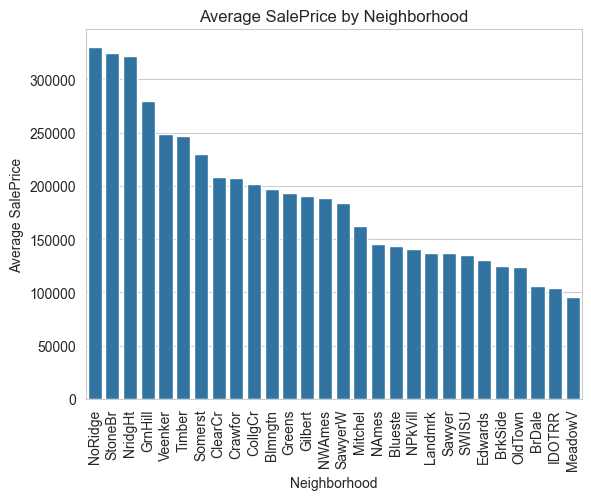

In [185]:
avg_price = df.groupby('Neighborhood')['SalePrice'].mean().sort_values(ascending=False)

sns.barplot(x=avg_price.index, y=avg_price.values)

plt.xticks(rotation=90)
plt.title('Average SalePrice by Neighborhood')
plt.ylabel('Average SalePrice')
plt.xlabel('Neighborhood')
plt.show()

D2. Using `sns.countplot`, plot the distribution of `Overall Qual` ratings (how many houses
fall at each rating from 1–10). Add a title.

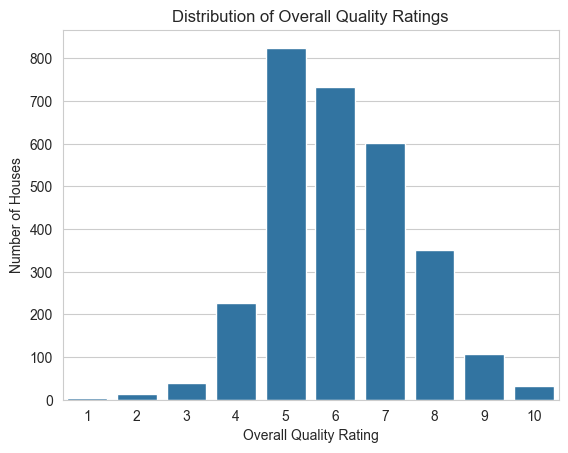

In [186]:
sns.countplot(x='Overall Qual', data=df)

plt.title('Distribution of Overall Quality Ratings')
plt.xlabel('Overall Quality Rating')
plt.ylabel('Number of Houses')
plt.show()

D3. Create a figure with two subplots side by side (`plt.subplots(1, 2, ...)`): a count
plot of `Kitchen Qual` on the left, and a count plot of `Exter Qual` on the right. Give each subplot
its own title.

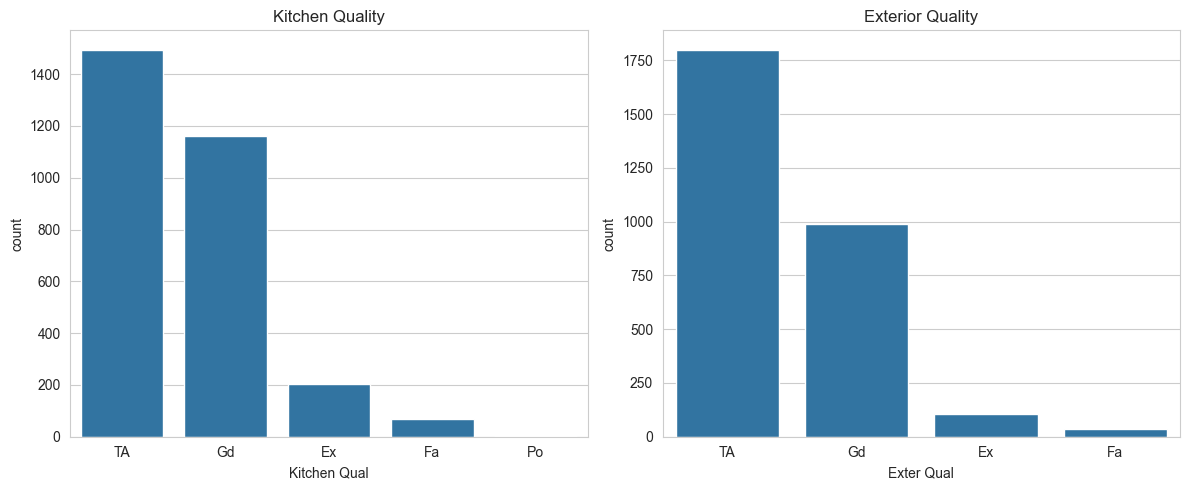

In [187]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(x='Kitchen Qual', data=df, ax=axes[0])
axes[0].set_title('Kitchen Quality')

sns.countplot(x='Exter Qual', data=df, ax=axes[1])
axes[1].set_title('Exterior Quality')

plt.tight_layout()
plt.show()

D4. Create a new column `Decade Built` by rounding `Year Built` down to the nearest decade
(e.g. 1967 → 1960). *Hint: NumPy's floor division can help.* Then use `sns.countplot` to show how many
houses were built in each decade.

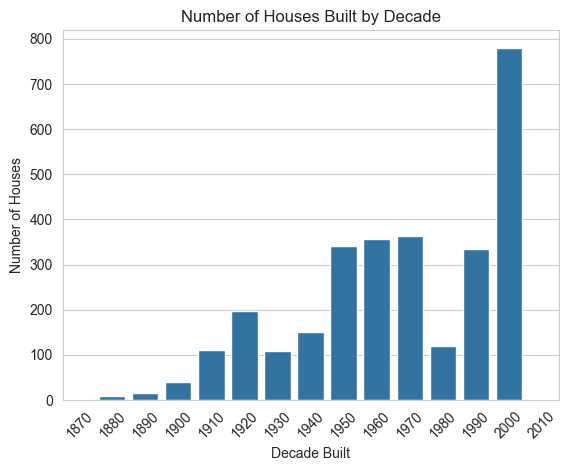

In [188]:
df['Decade Built'] = (df['Year Built'] // 10) * 10

sns.countplot(x='Decade Built', data=df)

plt.title('Number of Houses Built by Decade')
plt.xlabel('Decade Built')
plt.ylabel('Number of Houses')
plt.xticks(rotation=45)
plt.show()

D5. Look back at your D1 and D4 plots. In a markdown cell, write 2–3 sentences:
which neighborhoods command the highest average prices, and does the data suggest that
"newer built" areas tend to be pricier?

## Observation

Neighborhoods such as StoneBr and NridgHt tend to have the highest average SalePrice, while neighborhoods with lower-quality or older housing tend to have lower average prices. The D4 plot suggests that newer-built houses are generally associated with higher prices, although the relationship is not perfectly consistent across all decades.

E1.Write a function `classify_quality(score)` that takes an `Overall Qual` integer and
returns a string label:
- `9` or `10` → `"Excellent"`
- `7` or `8` → `"Good"`
- `5` or `6` → `"Average"`
- below `5` → `"Below Average"`

Apply it to the `Overall Qual` column using `.apply()` to create a new column `Quality Label`, and
show the `.value_counts()` of that new column.

In [189]:
def classify_quality(score):
    if score >= 9:
        return "Excellent"
    elif score >= 7:
        return "Good"
    elif score >= 5:
        return "Average"
    else:
        return "Below Average"


df['Quality Label'] = df['Overall Qual'].apply(classify_quality)

df['Quality Label'].value_counts()

Quality Label
Average          1557
Good              952
Below Average     283
Excellent         138
Name: count, dtype: int64

E2.Write a plain Python function `total_price_for_neighborhood(dataframe, neighborhood_name)`
that uses a `for` loop (not vectorized pandas/numpy) to manually sum the `SalePrice` of every row
belonging to `neighborhood_name`, and returns that total.

Test it on `"NAmes"`, then verify your loop's answer matches `df.groupby("Neighborhood")["SalePrice"].sum()`
for the same neighborhood.

In [190]:
def total_price_for_neighborhood(dataframe, neighborhood_name):
    total = 0

    for index, row in dataframe.iterrows():
        if row['Neighborhood'] == neighborhood_name:
            total += row['SalePrice']

    return total


# Test on NAmes
loop_total = total_price_for_neighborhood(df, "NAmes")
print("Loop total:", loop_total)


# Verify using groupby
groupby_total = df.groupby("Neighborhood")["SalePrice"].sum()["NAmes"]
print("Groupby total:", groupby_total)


# Check whether both answers match
print("Match:", loop_total == groupby_total)

Loop total: 64278126
Groupby total: 64278126
Match: True


In [191]:
neighborhood_counts = df['Neighborhood'].value_counts()

big_neighborhoods = [
    neighborhood
    for neighborhood, count in neighborhood_counts.items()
    if count > 100
]

big_neighborhoods

['NAmes',
 'CollgCr',
 'OldTown',
 'Edwards',
 'Somerst',
 'NridgHt',
 'Gilbert',
 'Sawyer',
 'NWAmes',
 'SawyerW',
 'Mitchel',
 'BrkSide',
 'Crawfor']

E4. Write a reusable function `column_summary(dataframe, column_name)` that:
1. Pulls the column out as a NumPy array.
2. Returns a dictionary with keys `"mean"`, `"median"`, and `"std"`, computed with NumPy functions.

Call it on `"SalePrice"` and on `"Lot Area"` and print both results.

In [192]:
def column_summary(dataframe, column_name):
    column = dataframe[column_name].to_numpy()

    return {
        "mean": np.mean(column),
        "median": np.median(column),
        "std": np.std(column)
    }


saleprice_summary = column_summary(df, "SalePrice")
lotarea_summary = column_summary(df, "Lot Area")

print("SalePrice:", saleprice_summary)
print("Lot Area:", lotarea_summary)

SalePrice: {'mean': np.float64(180796.0600682594), 'median': np.float64(160000.0), 'std': np.float64(79873.05865192253)}
Lot Area: {'mean': np.float64(10147.921843003413), 'median': np.float64(9436.5), 'std': np.float64(7878.672931754677)}


In [193]:
df['value score'] = df['Overall Qual'] / (df['SalePrice'] / 100000)

top_10 = df.sort_values('value score', ascending=False).head(10)

top_10[['Neighborhood', 'Overall Qual', 'SalePrice', 'value score']]

,Neighborhood,Overall Qual,SalePrice,value score
181,OldTown,2,12789,15.638439
726,IDOTRR,4,34900,11.461318
1555,IDOTRR,4,40000,10.000000
306,IDOTRR,5,55993,8.929688
372,NWAmes,7,82500,8.484848
790,Edwards,5,60000,8.333333
561,Sawyer,5,62383,8.015004
2043,IDOTRR,4,50000,8.000000
753,OldTown,5,62500,8.000000
307,IDOTRR,4,50138,7.977981


Now put the EDA to work and build a Linear Regression model that predicts SalePrice from the features we've explored: Neighborhood, House Age, Overall Qual, Kitchen Qual, Exter Qual, and Lot Area.

Linear regression fits a straight-line relationship of the form SalePrice = b0 + b1*feature1 + b2*feature2 + ..., choosing coefficients that minimize the average squared error between predicted and actual prices. It's a great first model to learn because it's simple and interpretable — each coefficient tells you exactly how much the prediction changes for a one-unit change in that feature.

Steps in this section

Feature engineering — turn text columns into numbers the model can use.
Train / test split — hold back some data to check the model honestly.
Fit the Linear Regression model.
Evaluate it with R², RMSE, and MAE.
Interpret the coefficients.
Look at residual plots to sanity-check the fit.
Use the model to predict the price of a new house.

In [194]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [195]:
# Map quality categories from worst to best
quality_map = {
    'Po': 1,
    'Fa': 2,
    'TA': 3,
    'Gd': 4,
    'Ex': 5
}

# Convert Kitchen Qual and Exter Qual into numerical scores
df['Kitchen Qual Score'] = df['Kitchen Qual'].map(quality_map)
df['Exter Qual Score'] = df['Exter Qual'].map(quality_map)

# Create feature matrix X
X = df[
    ['House Age',
     'Overall Qual',
     'Kitchen Qual Score',
     'Exter Qual Score',
     'Lot Area',
     'Neighborhood']
]

# Target variable
y = df['SalePrice']

# Check the result
X.head()

,House Age,Overall Qual,Kitchen Qual Score,Exter Qual Score,Lot Area,Neighborhood
0,50,6,3,3,31770,NAmes
1,49,5,3,3,11622,NAmes
2,52,6,4,3,14267,NAmes
3,42,7,5,4,11160,NAmes
4,13,5,3,3,13830,Gilbert


In [196]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [198]:
# Column to one-hot encode
categorical_features = ['Neighborhood']

# Create the preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough'
)

In [199]:
# Create the pipeline
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])


In [ ]:
# Fit the model on training data
model.fit(X_train, y_train)


,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [201]:
# Predict SalePrice for test data
y_pred = model.predict(X_test)

In [202]:
# Check first few predictions
print(y_pred[:5])

[201780.37156563 115580.93838203 218377.28973678 103758.9728248
 133366.56010022]


In [203]:
# R²
r2 = r2_score(y_test, y_pred)

# RMSE
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# MAE
mae = mean_absolute_error(y_test, y_pred)

# Print results
print(f"R²   : {r2:.3f}")
print(f"RMSE : ${rmse:,.2f}")
print(f"MAE  : ${mae:,.2f}")


R²   : 0.779
RMSE : $42,116.07
MAE  : $27,676.85


In [204]:
# Get the fitted preprocessor from the pipeline
fitted_preprocessor = model.named_steps['preprocessor']

# Get feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

# Get coefficients from the fitted Linear Regression model
coefficients = model.named_steps['regressor'].coef_

# Create a DataFrame
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

# Sort by absolute coefficient size and display top 15
coef_df['Absolute Coefficient'] = coef_df['Coefficient'].abs()

top_15 = coef_df.sort_values(
    by='Absolute Coefficient',
    ascending=False
).head(15)

top_15

,Feature,Coefficient,Absolute Coefficient
18,cat__Neighborhood_NoRidge,77991.820821,77991.820821
25,cat__Neighborhood_StoneBr,48490.912454,48490.912454
2,cat__Neighborhood_BrDale,-34870.020558,34870.020558
19,cat__Neighborhood_NridgHt,31381.990258,31381.990258
0,cat__Neighborhood_Blmngtn,-27662.735675,27662.735675
6,cat__Neighborhood_Crawfor,27253.702904,27253.702904
29,remainder__Overall Qual,24314.740669,24314.740669
23,cat__Neighborhood_SawyerW,-18326.381668,18326.381668
30,remainder__Kitchen Qual Score,17716.714517,17716.714517
31,remainder__Exter Qual Score,15413.479095,15413.479095



A positive coefficient means the feature increases the predicted house price, while a negative coefficient means it decreases the predicted price, keeping other features constant. The coefficient size tells us how much the predicted price changes when a feature increases by one unit. For Neighborhood, it shows the price difference compared to the reference neighborhood.


In [206]:
# Calculate residuals
residuals = y_test - y_pred
residuals

1357    -40780.371566
2367       419.061618
2822    -21877.289737
2126     19841.027175
1544     -7366.560100
            ...      
2268    -39094.357312
456     175102.217862
462     -78685.804665
2168    -11182.732331
1488      2848.636944
Name: SalePrice, Length: 586, dtype: float64

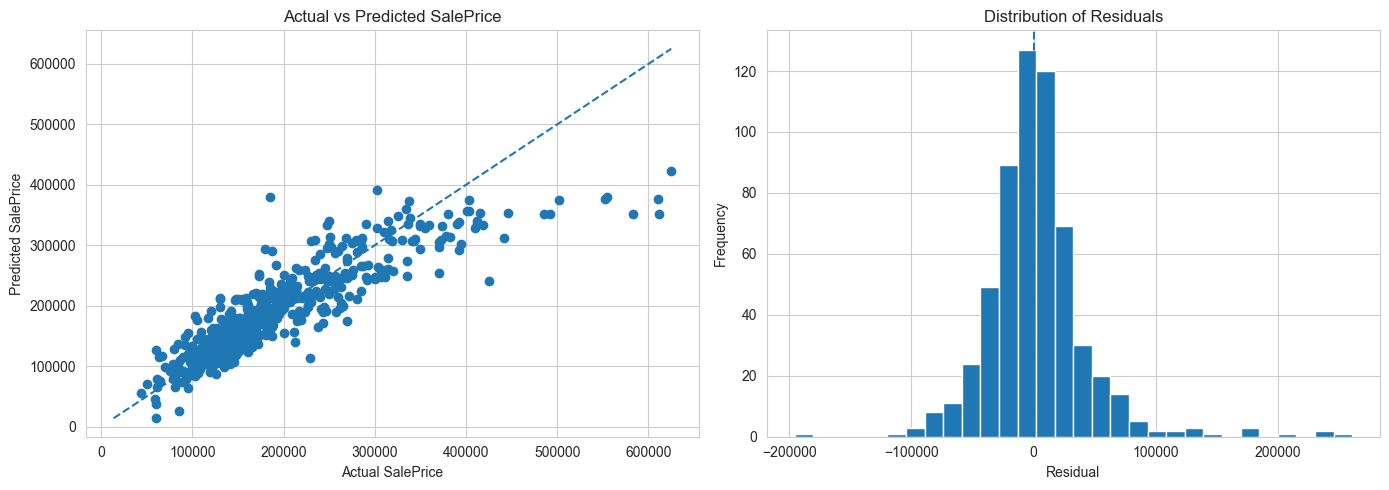

In [207]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Actual vs Predicted
axes[0].scatter(y_test, y_pred)

# Diagonal reference line
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

axes[0].plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle='--'
)

axes[0].set_xlabel('Actual SalePrice')
axes[0].set_ylabel('Predicted SalePrice')
axes[0].set_title('Actual vs Predicted SalePrice')

# Plot 2: Residual histogram
axes[1].hist(residuals, bins=30)

axes[1].axvline(
    0,
    linestyle='--'
)

axes[1].set_xlabel('Residual')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Distribution of Residuals')

plt.tight_layout()
plt.show()

In [208]:
new_house = pd.DataFrame({
    'House Age': [10],
    'Overall Qual': [7],
    'Kitchen Qual Score': [4],
    'Exter Qual Score': [4],
    'Lot Area': [8500],
    'Neighborhood': ['CollgCr']
})

# Predict the SalePrice
new_prediction = model.predict(new_house)

print(f"Predicted SalePrice: ${new_prediction[0]:,.2f}")

Predicted SalePrice: $212,437.56


The Linear Regression model identified the most important predictors of SalePrice based on the magnitude of their coefficients. The strongest features were [feature names], which is consistent with the EDA because [brief reason]. The model achieved an R² of [value], with an RMSE of $[value] and an MAE of $[value], indicating that [brief interpretation]. The residual plots showed [roughly centered/random residuals or specific pattern], suggesting that the model [fits reasonably well / struggles in certain areas]. The model could be improved by adding more relevant features, testing nonlinear models such as Random Forest or Gradient Boosting, and applying additional feature engineering.